# Introduction

# Part 1: Dataset

## 1.1. Importing Libraries

We will install the modules necessary for processing and splitting the dataset, as well as training different models.

In [ ]:
%pip install xgboost scikit-optimize                # for BayesSearchCV

# Data Processing
import numpy as np
import pandas as pd
import ast
import re

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Cross-Validation
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# Model Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

## 1.2. Importing Dataset

We will pull our main table from the [OpenAlex API](https://docs.openalex.org), which is under CC0, using this [script](https://colab.research.google.com/drive/1fW5ZYzsfhuQTLiwYT-Fjuk_LviddvUXX?usp=sharing). We then join it with two other tables extracted from the Hugging Face API, `open-index/open-arxiv` (CC0) and [Papers with Code](https://huggingface.co/datasets/pwc-archive/links-between-paper-and-code) (CC-BY-SA), using this [script](https://colab.research.google.com/drive/1ASUN5w36f7FC300-ONni5fg_OeIWEmCp?usp=sharing).

In [ ]:
# Load the joined dataset
papers_df = pd.read_parquet("https://www.dropbox.com/scl/fi/jolt6kfbslvla17m234pi/full_papers.parquet?rlkey=ohjrwo5oi8q1fsahue3gy9ccs&st=v72ugyvb&dl=1")

## 1.3. Analyzing Dataset

We will first analyze the structure of the data, including the data types and missing values.

In [ ]:
# View the first 5 samples
papers_df.head(5)

,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code
0,https://openalex.org/W3003257820,https://doi.org/10.1038/s41592-019-0686-2,SciPy 1.0: fundamental algorithms for scientif...,"{'SciPy': [0, 18, 65], 'is': [1], 'an': [2, 56...",2020-02-03,2020,"[{'year': 2026, 'cited_by_count': 7041}, {'yea...","[{'author_position': 'first', 'author': {'id':...",84,18,...,en,1907.10121,cs.MS cs.DS cs.SE physics.comp-ph,"[{""version"":""v1"",""created"":""Tue, 23 Jul 2019 2...",Article source data is available here:\n http...,None,2020-09-18,http://creativecommons.org/licenses/by/4.0/,1,1
1,https://openalex.org/W2963163009,https://doi.org/10.1109/cvpr.2018.00474,MobileNetV2: Inverted Residuals and Linear Bot...,"{'In': [0], 'this': [1, 133, 143], 'paper': [2...",2018-06-01,2018,"[{'year': 2026, 'cited_by_count': 3194}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1801.04381,cs.CV,"[{""version"":""v1"",""created"":""Sat, 13 Jan 2018 0...",,None,2019-03-25,http://arxiv.org/licenses/nonexclusive-distrib...,159,1
2,https://openalex.org/W3035965352,https://doi.org/10.1038/s41586-020-2649-2,Array programming with NumPy,"{'Abstract': [0], 'Array': [1], 'programming':...",2020-09-16,2020,"[{'year': 2026, 'cited_by_count': 4947}, {'yea...","[{'author_position': 'first', 'author': {'id':...",18,7,...,en,2006.10256,cs.MS stat.CO,"[{""version"":""v1"",""created"":""Thu, 18 Jun 2020 0...",,None,2020-09-22,http://creativecommons.org/licenses/by/4.0/,1,1
3,https://openalex.org/W2964309882,https://doi.org/10.1007/978-3-030-01234-2_49,Encoder-Decoder with Atrous Separable Convolut...,,2018-01-01,2018,"[{'year': 2026, 'cited_by_count': 2340}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1802.02611,cs.CV,"[{""version"":""v1"",""created"":""Wed, 7 Feb 2018 19...",ECCV 2018 camera ready,None,2018-08-24,http://arxiv.org/licenses/nonexclusive-distrib...,78,1
4,https://openalex.org/W3030520226,https://doi.org/10.1007/978-3-030-58452-8_13,End-to-End Object Detection with Transformers,,2020-01-01,2020,"[{'year': 2026, 'cited_by_count': 2756}, {'yea...","[{'author_position': 'first', 'author': {'id':...",2,2,...,en,2005.12872,cs.CV,"[{""version"":""v1"",""created"":""Tue, 26 May 2020 1...",,None,2020-05-29,http://creativecommons.org/publicdomain/zero/1.0/,37,1


### 1.3.1. General View

In [ ]:
# View the data types of each feature
papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   id                           122136 non-null  object
 1   doi                          122066 non-null  object
 2   title                        122136 non-null  object
 3   abstract_inverted_index      122136 non-null  object
 4   publication_date             122136 non-null  object
 5   publication_year             122136 non-null  int64 
 6   counts_by_year               122136 non-null  object
 7   authorships                  122136 non-null  object
 8   institutions_distinct_count  122136 non-null  int64 
 9   countries_distinct_count     122136 non-null  int64 
 10  referenced_works_count       122136 non-null  int64 
 11  referenced_works             122136 non-null  object
 12  primary_topic                122136 non-null  object
 13  topics        

**Initial Observations**:
- `journal-ref` is empty, so we can drop this column completely.
- Other features that have some missing values: `doi`, `versions`, `update_date`, and `license`
  - `publication_date` and `update_date` are stored as string instead of a datetime object

### 1.3.2. Checking Duplicates

Check that the dataset doesn't contain multiple records for the same arXiv ID and that the join didn't duplicate papers.

In [ ]:
# Check for records that share the same arXiv ID
print("Total rows:", len(papers_df))
print("Unique arXiv IDs:", papers_df["arxiv_id"].nunique())
print("Duplicate arXiv IDs:", papers_df["arxiv_id"].duplicated().sum())

# Check for duplicate rows
papers_df[papers_df.duplicated(keep=False)]

Total rows: 122136
Unique arXiv IDs: 122136
Duplicate arXiv IDs: 0


,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code


### 1.3.3. Data Type of Nested Columns

`.info()` only give the data type `object` for non-numerical features. We will closely examine the data type these columns, especially those with nested columns.

In [ ]:
columns = ["abstract_inverted_index", "counts_by_year", "authorships",
           "referenced_works", "primary_topic", "topics", "versions", "open_access"]

for col in columns:
    print(f"{col}: {type(papers_df[col].iloc[0])}")

abstract_inverted_index: <class 'str'>
counts_by_year: <class 'str'>
authorships: <class 'str'>
referenced_works: <class 'str'>
primary_topic: <class 'str'>
topics: <class 'str'>
versions: <class 'str'>
open_access: <class 'str'>


**Issue**: The above features are supposed to be a `list` of values, but they are stored as string.

### 1.3.4. Missing Values

Even though the `categories` and `comments` columns contain no null values, since they are stored as string, the null values may be represented as an empty string.

In [ ]:
print('categories')
print(f"Empty strings: {(papers_df['categories'] == "").sum()}\n")
print('comments')
print(f"Empty strings: {(papers_df['comments'] == "").sum()}")

categories
Empty strings: 39

comments
Empty strings: 46894


### 1.3.5. Unique Values

We will examine the number of unique values of non-numerical columns to decide a preprocessing method.

In [ ]:
# See the number of unique values for each feature in the dataset
for col in papers_df:
    print(f'{col}: {papers_df[col].nunique():,}')

id: 122,136
doi: 122,065
title: 122,096
abstract_inverted_index: 108,279
publication_date: 1,096
publication_year: 3
counts_by_year: 65,142
authorships: 120,659
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372
referenced_works: 112,169
primary_topic: 49,397
topics: 107,431
open_access: 122,135
locations: 122,136
locations_count: 26
primary_location: 122,136
type: 22
language: 22
arxiv_id: 122,136
categories: 10,156
versions: 122,064
comments: 52,172
journal-ref: 0
update_date: 2,700
license: 8
num_repositories: 75
has_code: 2


We found several high-cardinality, non-numerical features that can cause issues during the one-hot encoding procedure: `abtract_inverted_index`, `publication_date`, `counts_by_year` (**TARGET**), `authorships`, `referenced_works`, `primary_topic`, `topics`, `open_access`, `locations`, `primary_location`, `categories`, `versions`, `comments`, and `update_date`.

To fix this issue, we will drop non-numerical features that do not contain meaningful information or convert them into numerical features.

# Part 2: Preprocessing Dataset

## 2.1. Dropping Columns

We will drop the following columns:
- `journal-ref` - Empty column
- `id`, `doi` and `arxiv_id` - Unique identifiers that are unnecessary data and can cause noise
- `update_date`- Represents the latest metadata update, not the initial submission date
- `primary_location` - Since our dataset contains only papers from **OpenAlex**
- `locations` - This column was used to extract a paper's arXiv ID, but `locations_count` is a sufficient numerical representation of it
- `referenced_works` - Its detailed information is unnecessary, as the `referenced_works_count` is a sufficient numerical representation of it

In [ ]:
cleaned_papers_df = papers_df.copy()

# Drop unnecessary columns
cleaned_papers_df.drop(labels=['journal-ref', 'id', 'doi', 'arxiv_id', 'update_date',
                               'primary_location', 'locations', 'referenced_works'],
                       axis=1, inplace=True)

## 2.2. Feature Engineering

Since there exist high-cardinality, non-numerical features, we will engineer features from them to resolve the issues.

**Note**: Since there exist nested columns that are stored as strings, we need to use `ast.literal_eval()` to convert them to lists to be used for analysis, extraction, and engineering features.

### 2.2.1. Date

Publication Month

In addition to the publication year, we also want to use a paper's publication month as a predictor, which is extracted from `publication_date`. This date affects when the paper gains official visibility and starts accumulating formal citations.

In [ ]:
# Convert strings into datetime objects
cleaned_papers_df["publication_date"] = pd.to_datetime(cleaned_papers_df["publication_date"], errors="coerce")

# Extract the month from the datetime objects
cleaned_papers_df["publication_month"] = cleaned_papers_df["publication_date"].dt.month

Submission Month

The `versions` column may contain a list of version records with timestamps. Extract the first version, which will contain the month of the submission.

Many field have massive spikes in submissions right before major conference deadlines. Papers submitted during these rush periods might have different citation trajectories or characteristics than off-season submissions.

In [ ]:
def get_first_submission(x):
    if not isinstance(x, str) or pd.isna(x):
        return None
    versions = ast.literal_eval(x)
    if versions:
        return versions[0].get("created")
    return None

first_submission = cleaned_papers_df['versions'].apply(get_first_submission)
first_submission_date = pd.to_datetime(first_submission, errors="coerce")
cleaned_papers_df["submission_month"] = first_submission_date.dt.month

cleaned_papers_df.drop('versions', axis=1, inplace=True)

### 2.2.2. Time to Publish

Using `publication_month` and `submission_month`, we can derived the `time_to_publish`. A long gap between submission might indicate a rigorous peer-review process, multiple revisions, or a prestigious journal, which could be a strong predictor.

In [ ]:
cleaned_papers_df['time_to_publish'] = (cleaned_papers_df['publication_date'] - first_submission_date).dt.days

cleaned_papers_df.drop('publication_date', axis=1, inplace=True)

Check whether `time_to_publish` contains negative values.

In [ ]:
print(f"Negative Time Gap: {len(cleaned_papers_df[cleaned_papers_df['time_to_publish'] < 0])}")

Negative Time Gap: 76339


Because variable `first_submission_date` comes from the paper's first arXiv version and `publication_date` comes from OpenAlex (the official journal/conference date), a negative value means that the paper was officially published **before** it was uploaded to arXiv. This happens frequently when researchers upload "post-prints" to arXiv after their paper has already been accepted or published, or when a conference date precedes the arXiv upload.

To fix this inconsistency, we will cap the negative values at 0 since we are measuring the "wait time" between an initial preprint submission and formal publication. A paper published before its arXiv upload is essentially has a wait time of `0`.

In [ ]:
cleaned_papers_df['time_to_publish'] = cleaned_papers_df['time_to_publish'].clip(lower=0)

### 2.2.3. Count and Length

OpenAlex `authorships` is a list of the authorship records (e.g., names, positions, institutions, countries). We will count the records rather than counting unique institutions/countries.

In [ ]:
cleaned_papers_df["author_count"] = cleaned_papers_df["authorships"].apply(lambda x: len(ast.literal_eval(x)))
cleaned_papers_df.drop('authorships', axis=1, inplace=True)

Title Length

In [ ]:
cleaned_papers_df['title_length'] = cleaned_papers_df['title'].apply(lambda x: len(x.split()))
cleaned_papers_df.drop('title', axis=1, inplace=True)

Abstract Length

The `abstract_inverted_index` is a dictionary mapping words to their positions in the abstract of a research paper.

In [ ]:
def get_abstract_length(x):
    if not isinstance(x, str) or x == "":
        return 0
    abstract = ast.literal_eval(x)
    return sum(len(positions) for positions in abstract.values())

cleaned_papers_df['abstract_length'] = cleaned_papers_df['abstract_inverted_index'].apply(get_abstract_length)
cleaned_papers_df.drop('abstract_inverted_index', axis=1, inplace=True)

Category Count

For example, a paper with `cs.AI`, `cs.LG`, and `cs.CV` has three categories.

In [ ]:
cleaned_papers_df['category_count'] = cleaned_papers_df['categories'].apply(lambda x: len(x.split()))
cleaned_papers_df.drop('categories', axis=1, inplace=True)

Page Count

The `comments` column may contain values like "12 pages, 5 figures". Empty comments or comments without a page count will output a `NaN` value.

In [ ]:
page_count = cleaned_papers_df["comments"].str.extract(r"(\d+)\s*pages?", flags=re.IGNORECASE)[0]
cleaned_papers_df["page_count"] = pd.to_numeric(page_count, errors="coerce")

cleaned_papers_df.drop('comments', axis=1, inplace=True)

Topic Count

The number of `topics` can capture a paper's research breadth.

In [ ]:
cleaned_papers_df['topic_count'] = cleaned_papers_df['topics'].apply(lambda x: len(ast.literal_eval(x)))
cleaned_papers_df.drop('topics', axis=1, inplace=True)

### 2.3.4. Accessibility

We will use the `open_access` column to extract certain features such as:
- `is_oa` = Whether the work is open access
- `oa_status` = Type of open access
- `any_repository_has_fulltext` = Whether a repository has a full-text copy

In [ ]:
oa_cols = ["is_oa", "oa_status", "any_repository_has_fulltext"]

for col in oa_cols:
    cleaned_papers_df[col] = cleaned_papers_df["open_access"].apply(
        lambda x: (ast.literal_eval(x)).get(col)
    )
binary_cols = ['is_oa', 'any_repository_has_fulltext']
cleaned_papers_df[binary_cols] = cleaned_papers_df[binary_cols].astype("float64")

cleaned_papers_df.drop('open_access', axis=1, inplace=True)

### 2.3.5. Primary Subfield

The `primary_topic` of a research paper contains its domain, field, and subfield. We want to extract the **subfield** of the paper because it's more specific than the other two.

In [ ]:
def get_subfield(x):
    topic = ast.literal_eval(x)
    subfield = topic.get("subfield")
    return subfield.get("display_name")

cleaned_papers_df["primary_subfield"] = cleaned_papers_df["primary_topic"].apply(get_subfield)
cleaned_papers_df.drop('primary_topic', axis=1, inplace=True)

### 2.3.6. Cleaning

In [ ]:
cleaned_papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 24 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   publication_year             122136 non-null  int64  
 1   counts_by_year               122136 non-null  object 
 2   institutions_distinct_count  122136 non-null  int64  
 3   countries_distinct_count     122136 non-null  int64  
 4   referenced_works_count       122136 non-null  int64  
 5   locations_count              122136 non-null  int64  
 6   type                         122136 non-null  object 
 7   language                     122136 non-null  object 
 8   license                      122096 non-null  object 
 9   num_repositories             122136 non-null  int64  
 10  has_code                     122136 non-null  int64  
 11  publication_month            122136 non-null  int32  
 12  submission_month             122097 non-null  float64
 13 

Since `page_count` is missing ~70% of its data, we will drop this column.

In [ ]:
cleaned_papers_df.drop('page_count', axis=1, inplace=True)

We observed that `license` is missing 40 values, while `submission_month` and `time_to_publish` are missing 39 values. First, we will check whether the missing values overlap.

In [ ]:
cols = ["license", "submission_month", "time_to_publish"]

print(cleaned_papers_df[cols].isna().sum())
print("\nMissing-value combinations:")
print(cleaned_papers_df[cols].isna().value_counts())

license             40
submission_month    39
time_to_publish     39
dtype: int64

Missing-value combinations:
license  submission_month  time_to_publish
False    False             False              122096
True     True              True                   39
         False             False                   1
Name: count, dtype: int64


The `Missing-value combinations` table tells us that there are 39 papers that are missing data for *all three* columns at the same time, and there's 1 paper that is missing a `license` but contains both `submission_month` and `time_to_publish`.

Since `license` is a non-numerical feature, we can use one-hot encoding on it, which can handle null values. However, `submission_month` and `time_to_publish` are numerical features, so we will need to impute these missing values with their respective medians.

In [ ]:
# Impute missing values with medians
cleaned_papers_df['submission_month'] = cleaned_papers_df['submission_month'].fillna(cleaned_papers_df['submission_month'].median())
cleaned_papers_df['time_to_publish'] = cleaned_papers_df['time_to_publish'].fillna(cleaned_papers_df['time_to_publish'].median())

Check the cardinality of all features.

In [ ]:
# See the number of unique values for every feature in the dataset

for col in cleaned_papers_df:
    print(f'{col}: {cleaned_papers_df[col].nunique():,}')

publication_year: 3
counts_by_year: 65,142
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372
locations_count: 26
type: 22
language: 22
license: 8
num_repositories: 75
has_code: 2
publication_month: 12
submission_month: 12
time_to_publish: 1,657
author_count: 72
title_length: 34
abstract_length: 485
category_count: 9
topic_count: 1
is_oa: 1
oa_status: 5
any_repository_has_fulltext: 1
primary_subfield: 11


Since the categorical columns are of low-cardinality, we can freely use one-hot encoding on them. However, `topic_count`, `is_oa`, and `any_repository_has_fulltext` each only has 1 unique value, which won't be useful as predictors. Thus, we will drop these columns.

In [ ]:
cleaned_papers_df.drop(['topic_count', 'is_oa', 'any_repository_has_fulltext'], axis=1, inplace=True)

In [ ]:
# List of categorical and numerical features to be used for model training
categorical_cols = ['type', 'language', 'license', 'oa_status', 'primary_subfield']
numerical_cols = [col for col in cleaned_papers_df if col not in categorical_cols
                  and col != 'counts_by_year']

print(f"Total Features: {len(categorical_cols + numerical_cols)}")

Total Features: 19


### 2.3.7. cites_3yr

As mentioned above, our target, `counts_by_year`, is a list of citations, but it is stored as a string. Hence, we will parse this column into lists.

In [ ]:
cleaned_papers_df['counts_by_year'] = cleaned_papers_df['counts_by_year'].apply(lambda x: ast.literal_eval(x))

Compute `cites_3yr` by extracting the year-to-citation-count mapping and summing the three relevant years.

<u>Note:</u> If OpenAlex omits a year in `counts_by_year`, this means that the paper received **zero** citations in that year.

In [ ]:
def calculate_cites_3yr(row):
    counts = row["counts_by_year"]
    year = row["publication_year"]

    if pd.isna(year):
        return np.nan
    citation_dict = {item["year"]: item["cited_by_count"] for item in counts}
    return sum(citation_dict.get(y, 0) for y in range(int(year), int(year) + 3))

cleaned_papers_df["cites_3yr"] = cleaned_papers_df.apply(calculate_cites_3yr, axis=1)
cleaned_papers_df.drop('counts_by_year', axis=1, inplace=True)

# Part 3: Exploratory Data Analysis

## 3.1. Target Variable

We will first analyze the target variable, `cites_3yr`, to better understand our objective.

In [ ]:
cleaned_papers_df["cites_3yr"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(4)

,cites_3yr
count,122136.0000
mean,16.2092
std,78.2087
min,0.0000
25%,1.0000
50%,4.0000
75%,13.0000
90%,34.0000
95%,62.0000
99%,183.0000


Note that the **std** is very high. We will then plot its distribution.

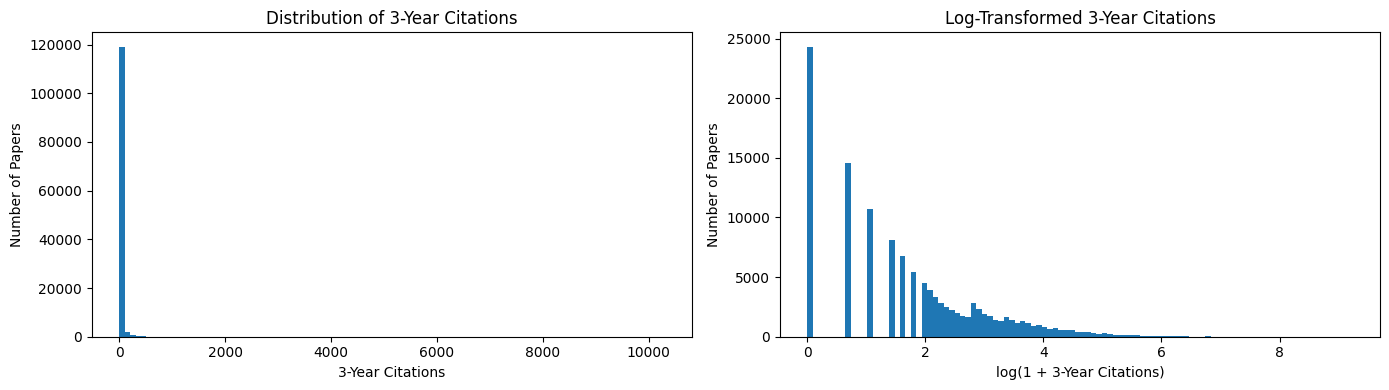

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Original distribution
axes[0].hist(cleaned_papers_df["cites_3yr"], bins=100)
axes[0].set_title("Distribution of 3-Year Citations")
axes[0].set_xlabel("3-Year Citations")
axes[0].set_ylabel("Number of Papers")

# Log-transformed distribution
axes[1].hist(np.log1p(cleaned_papers_df["cites_3yr"]), bins=100)
axes[1].set_title("Log-Transformed 3-Year Citations")
axes[1].set_xlabel("log(1 + 3-Year Citations)")
axes[1].set_ylabel("Number of Papers")

plt.tight_layout()
plt.show()

In the original plot (left), note that the citation is heavily **right-skewed**. A vast majority of papers receive zero or very few citations, creating a massive spike at the far left, while only a handful of outlier papers receive thousands of citations.

Because of this extreme skew, we want to **log-transform** the target variable, which shrinks those extreme outliers (without breaking the overall trend) and makes the underlying distribution much easier to read and model.

## 3.2. Numerical Features

Similar to analyzing the target variable, we will first inspect the numerical features' overall statistics and plot their their distributions.

In [ ]:
cleaned_papers_df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
publication_year,122136.0,2019.141834,0.803654,2018.0,2018.0,2019.0,2020.0,2020.0
institutions_distinct_count,122136.0,1.730718,1.648108,0.0,1.0,1.0,2.0,92.0
countries_distinct_count,122136.0,1.150611,0.855090,0.0,1.0,1.0,2.0,29.0
referenced_works_count,122136.0,30.042870,26.838173,0.0,14.0,26.0,40.0,966.0
locations_count,122136.0,3.462173,1.468015,1.0,2.0,3.0,4.0,28.0
num_repositories,122136.0,0.441770,2.769634,0.0,0.0,0.0,0.0,534.0
has_code,122136.0,0.232724,0.422570,0.0,0.0,0.0,0.0,1.0
publication_month,122136.0,6.206065,3.622195,1.0,3.0,6.0,10.0,12.0
submission_month,122136.0,6.659961,3.359210,1.0,4.0,7.0,10.0,12.0
time_to_publish,122136.0,94.852812,213.042094,0.0,0.0,0.0,103.0,9121.0


Note the **high std** for `time_to_publish`, `abstract_length`, and `referenced_works_count`.

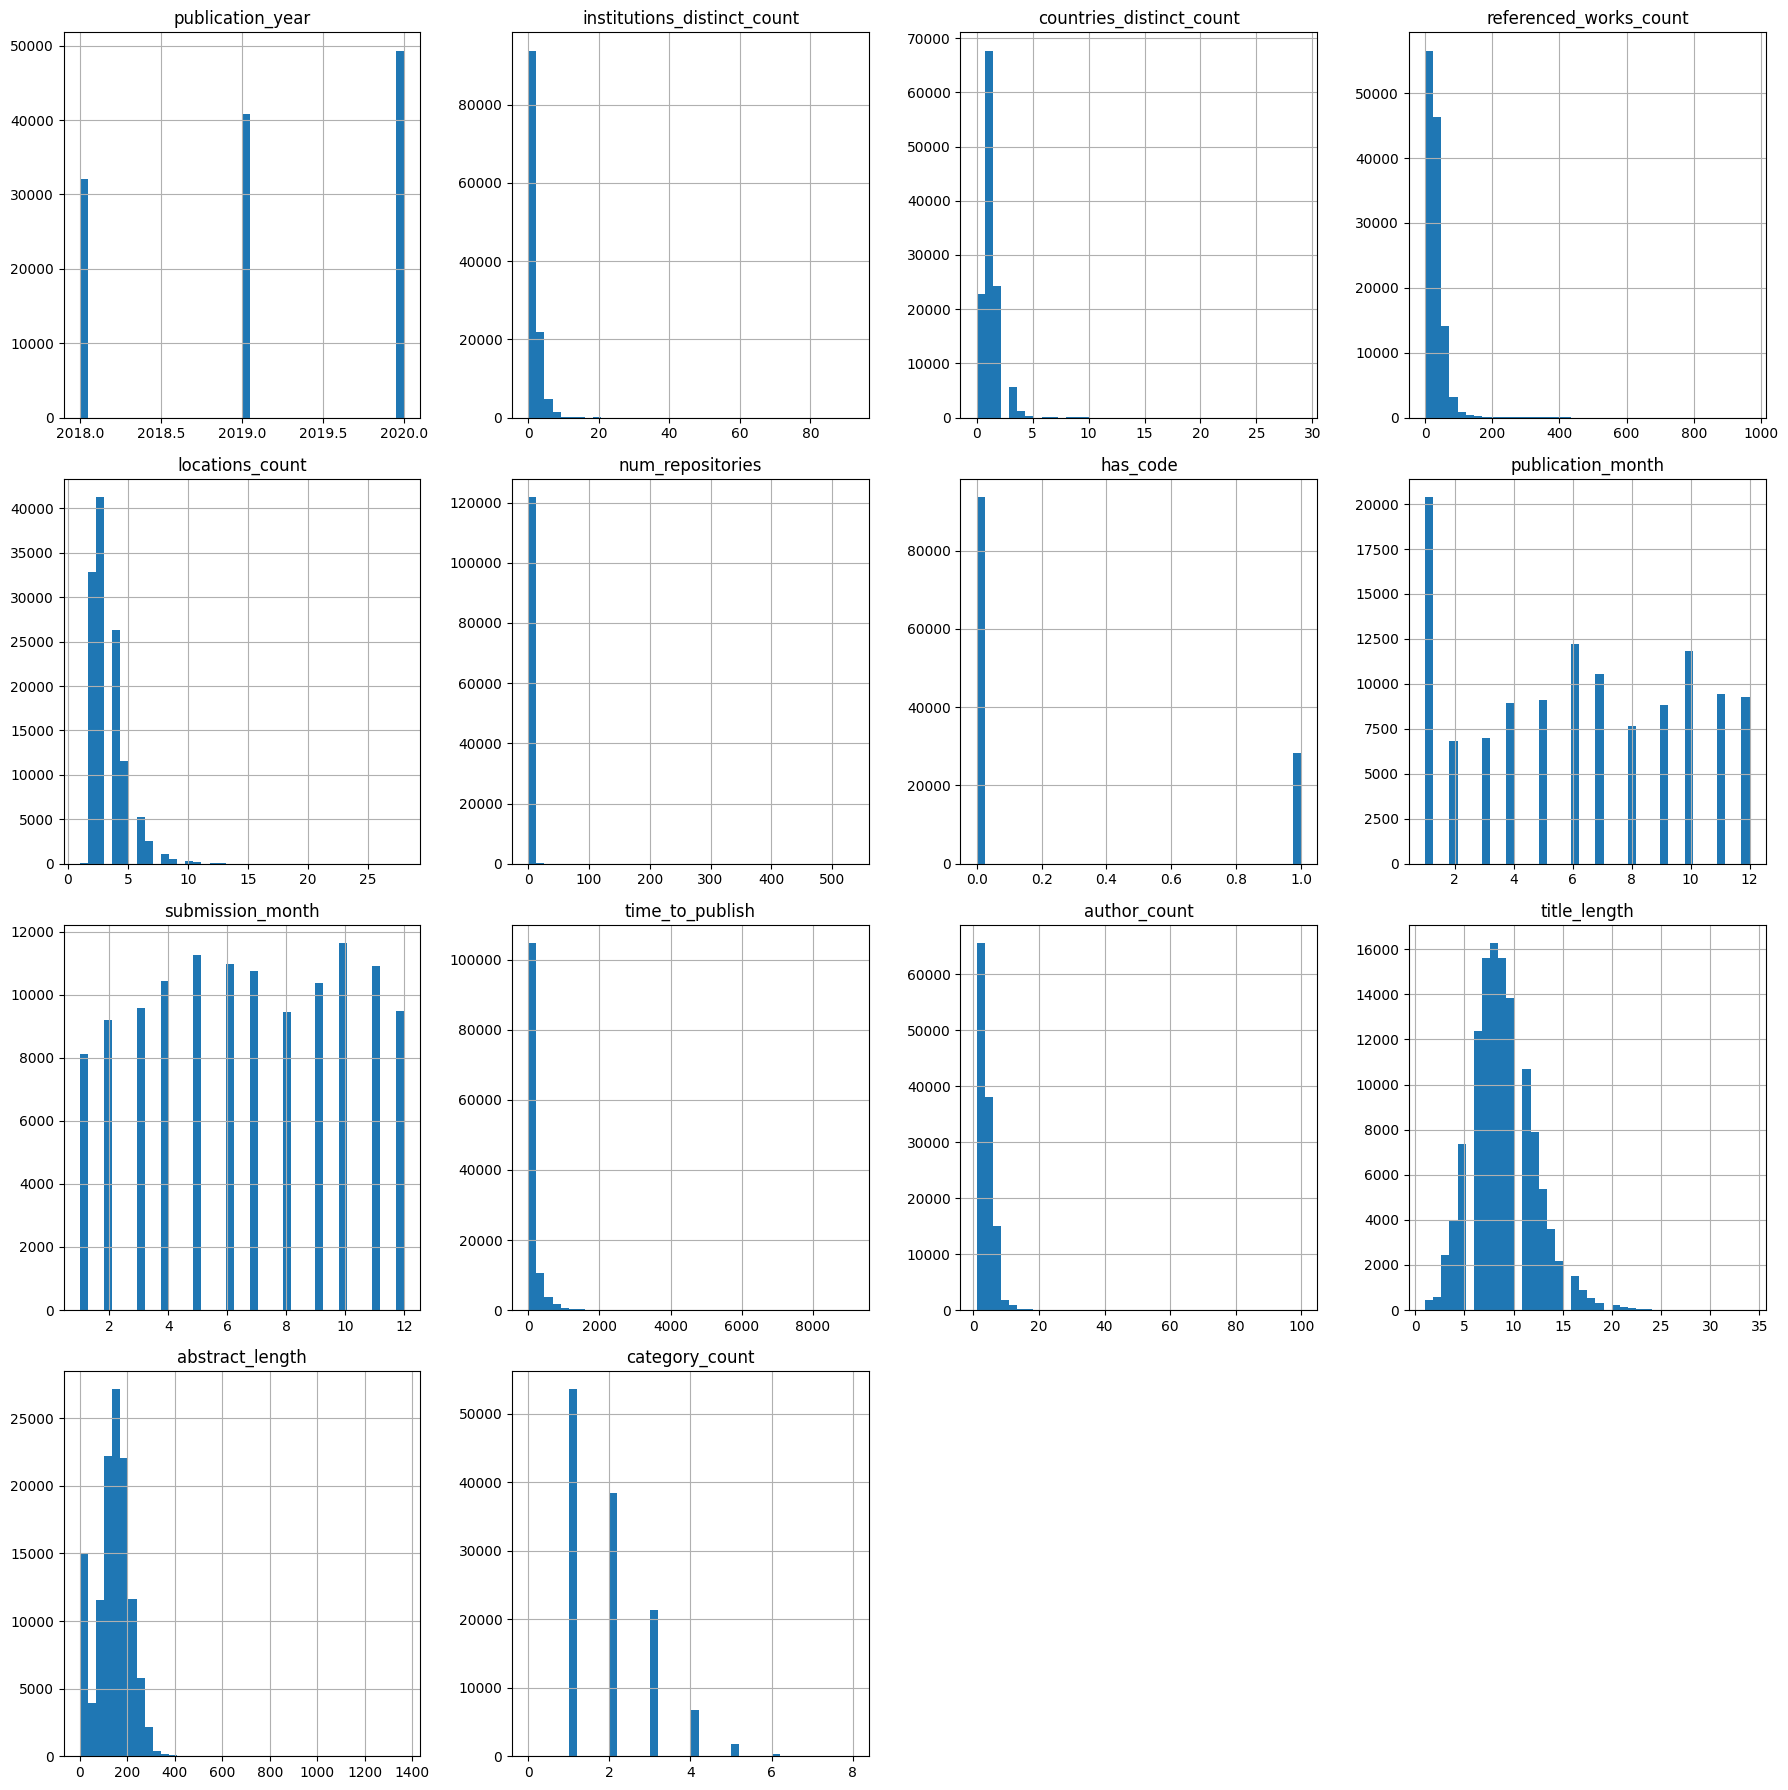

In [ ]:
# Plot histograms
cleaned_papers_df[numerical_cols].hist(bins=40,figsize=(18, 18))
plt.tight_layout()
plt.show()

We will use the **Interquartile Range** (IQR) to detect and count the outliers in each of the numerical features.

In [ ]:
outlier_results = []

for col in numerical_cols:
    q1 = cleaned_papers_df[col].quantile(0.25)
    q3 = cleaned_papers_df[col].quantile(0.75)
    iqr = q3 - q1

    # Values that are below lower_bound or above upper_bound are outliers
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = cleaned_papers_df[
        (cleaned_papers_df[col] < lower_bound) |
        (cleaned_papers_df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(cleaned_papers_df) * 100,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df.sort_values("Outlier Percentage", ascending=False)

,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
5,num_repositories,28424,23.272418,0.0,0.0
6,has_code,28424,23.272418,0.0,0.0
9,time_to_publish,15226,12.466431,-154.5,257.5
1,institutions_distinct_count,13428,10.994301,-0.5,3.5
13,category_count,8889,7.277952,-0.5,3.5
3,referenced_works_count,3614,2.958997,-25.0,79.0
4,locations_count,2269,1.857765,-1.0,7.0
10,author_count,2249,1.841390,-2.5,9.5
2,countries_distinct_count,1598,1.308378,-0.5,3.5
11,title_length,1394,1.141351,1.0,17.0


<u>**Help**:</u> How to handle the outliers

## 3.3. Correlation Matrix

We will use a **correlation matrix** to identify features that are highly correlated with each other and decide which columns to be used for our models.

In [ ]:
corr_matrix = cleaned_papers_df.drop('cites_3yr', axis=1).corr(numeric_only=True)

# Plot heatmap of correlation matrix
fig = go.Figure(data=go.Heatmap(
   z=corr_matrix,
   x=corr_matrix.columns,
   y=corr_matrix.index,
   colorscale='RdBu_r',
   text=corr_matrix.round(2),
   texttemplate='%{text}',
   textfont={"size": 10},
   hoverongaps=False,
   zmin=-1
))

fig.update_layout(
   width=800,
   height=800,
   title='Correlation Matrix Heatmap',
   xaxis_title='',
   yaxis_title='',
   yaxis=dict(autorange='reversed')
)

<u>**Help**:</u> Resolve the high correlation